# Ensemble Learning Dashboard: Forecasting Sri Lankan Rainfall
**Bagging vs Boosting vs Stacking vs Hybrid models** on WFP/CHIRPS dekadal (10-day) rainfall for Sri Lanka's 25 districts, 2022 to 2026.

> **AI-assistance disclosure:** Parts of this notebook's code were generated with the help of an AI assistant (Claude, by Anthropic) and then run, checked and interpreted by the student author.

**Task:** predict the rainfall total (mm) of the *next* 10-day period for each district, using only information available before that period starts.

**Why it matters in Sri Lanka:** rainfall drives paddy planting (Yala/Maha seasons), hydropower reservoirs, flood and landslide risk in the wet zone and drought in the dry zone. Sri Lanka has two monsoons (South-West: May to Sep, North-East: Dec to Feb) and two inter-monsoon periods, so seasonality is strong.

**Plan**
1. Explore the data  2. Engineer leak-free features  3. Train bagging, boosting and stacking models  4. Build hybrids (SARIMAX+RF, SARIMAX+LightGBM, RF+ANN)  5. Compare on a time-based hold-out with honest baselines  6. Interpret (importance, SHAP, seasons)  7. Export models for the Streamlit dashboard

In [1]:
import warnings, json, time, os, re, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import Ridge
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, r2_score
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from statsmodels.tsa.statespace.sarimax import SARIMAX
warnings.filterwarnings('ignore')
SEED = 42; np.random.seed(SEED)
DATA = 'data/lka-rainfall-subnat-5ytd.csv'
os.makedirs('models', exist_ok=True); os.makedirs('artifacts', exist_ok=True)
TEST_START = pd.Timestamp('2025-07-01')   # everything from here on is the unseen hold-out
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

## 1. Data and exploration

In [2]:
DISTRICTS = {'LK11':'Colombo','LK12':'Gampaha','LK13':'Kalutara','LK21':'Kandy','LK22':'Matale','LK23':'Nuwara Eliya',
 'LK31':'Galle','LK32':'Matara','LK33':'Hambantota','LK41':'Jaffna','LK42':'Kilinochchi','LK43':'Mannar','LK44':'Vavuniya',
 'LK45':'Mullaitivu','LK51':'Batticaloa','LK52':'Ampara','LK53':'Trincomalee','LK61':'Kurunegala','LK62':'Puttalam',
 'LK71':'Anuradhapura','LK72':'Polonnaruwa','LK81':'Badulla','LK82':'Monaragala','LK91':'Ratnapura','LK92':'Kegalle'}
raw = pd.read_csv(DATA)
d2 = raw[raw.adm_level == 2].copy(); d2['date'] = pd.to_datetime(d2['date']); d2['district'] = d2['PCODE'].map(DISTRICTS)
print('Rows (all levels):', len(raw), '| district-level rows:', len(d2))
print('Date range:', d2.date.min().date(), 'to', d2.date.max().date(), '| dekads per district:', d2.groupby('PCODE').size().unique())
print('Unmapped codes:', d2.district.isna().sum(), '| missing values:', int(d2.isna().sum().sum()))
print('Data versions:', d2.version.value_counts().to_dict(), '(prelim = most recent, not yet finalised)')
d2[['date','district','rfh','rfh_avg','r1h','r3h','rfq']].describe().round(1)

Rows (all levels): 5950 | district-level rows: 4375
Date range: 2022-01-01 to 2026-11-01 | dekads per district: [175]
Unmapped codes: 0 | missing values: 0
Data versions: {'final': 4275, 'prelim': 100} (prelim = most recent, not yet finalised)


,date,rfh,rfh_avg,r1h,r3h,rfq
count,4375,4375.0,4375.0,4375.0,4375.0,4375.0
mean,2024-05-31 16:43:53.142857,65.0,54.3,193.0,575.3,116.0
min,2022-01-01 00:00:00,0.0,0.0,0.0,1.0,5.4
25%,2023-03-11 00:00:00,12.5,23.0,62.1,282.2,55.9
50%,2024-06-01 00:00:00,40.6,46.3,145.2,519.1,93.3
75%,2025-08-21 00:00:00,95.6,77.9,284.0,827.3,154.0
max,2026-11-01 00:00:00,496.9,170.4,1101.4,2150.5,820.9
std,NaN,70.4,38.2,165.9,365.9,85.2


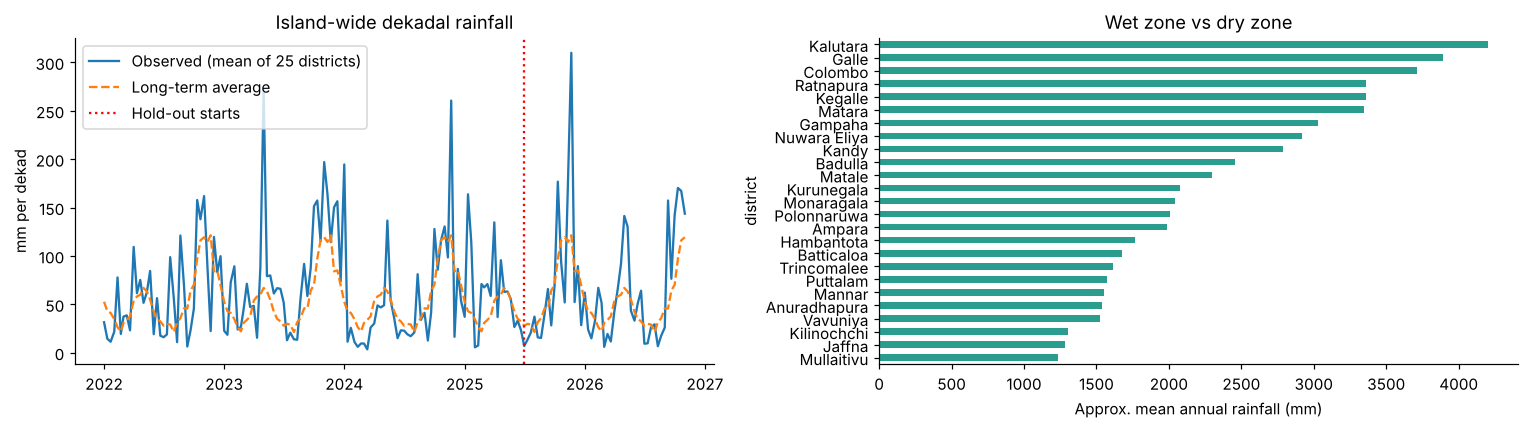

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
nat = d2.groupby('date')[['rfh', 'rfh_avg']].mean()
ax[0].plot(nat.index, nat.rfh, label='Observed (mean of 25 districts)'); ax[0].plot(nat.index, nat.rfh_avg, '--', label='Long-term average')
ax[0].axvline(TEST_START, color='red', ls=':', label='Hold-out starts'); ax[0].set_ylabel('mm per dekad'); ax[0].legend(); ax[0].set_title('Island-wide dekadal rainfall')
ann = (d2.groupby('district')['rfh'].mean() * 36).sort_values()
ann.plot.barh(ax=ax[1], color='#2a9d8f'); ax[1].set_xlabel('Approx. mean annual rainfall (mm)'); ax[1].set_title('Wet zone vs dry zone')
plt.tight_layout(); plt.show()

## 2. Feature engineering (leak-free)
Each row is **(district, dekad t)**. The target is `rfh` at *t*. All features come from dekads **before t**, plus things known in advance (calendar and the long-term average for that dekad). Shifting by one dekad stops the model peeking at the answer.

| Feature | Meaning |
|---|---|
| `lag1..lag4`, `roll3`, `roll6` | rainfall of the last 1 to 4 dekads, and mean of last 3 and 6 dekads |
| `r1h_l1`, `r3h_l1`, `rfq_l1`, `r1q_l1`, `r3q_l1` | 1-month and 3-month totals and anomalies (%) as of the previous dekad |
| `clim_t`, `clim_mean` | long-term average for the target dekad, and the district's overall wetness level |
| `sin1, cos1, sin2, cos2` | cyclical encoding of the position in the 36-dekad year |
| `monsoon` | 1 = South-West monsoon (May to Sep), 2 = North-East monsoon (Dec to Feb), 0 = inter-monsoon |

In [4]:
def dekad_idx(dt): return (dt.dt.month - 1) * 3 + np.minimum(dt.dt.day // 10, 2)      # 0..35
def next_dekad(ts):
    return ts + pd.Timedelta(days=10) if ts.day in (1, 11) else ts + pd.offsets.MonthBegin(1)
def fourier(dekad, K=3):
    ang = 2 * np.pi * np.asarray(dekad) / 36
    return np.column_stack([f(k * ang) for k in range(1, K + 1) for f in (np.sin, np.cos)])

BASE_FEATS = ['lag1','lag2','lag3','lag4','roll3','roll6','r1h_l1','r3h_l1','rfq_l1','r1q_l1','r3q_l1',
              'clim_t','clim_mean','sin1','cos1','sin2','cos2','monsoon']
HYB_FEATS = BASE_FEATS + ['arima']

def make_panel(raw, add_next=False):
    d = raw[raw.adm_level == 2].copy(); d['date'] = pd.to_datetime(d['date'])
    d = d.sort_values(['PCODE', 'date']).reset_index(drop=True); d['dekad'] = dekad_idx(d['date'])
    clim = d.groupby(['PCODE', 'dekad'])['rfh_avg'].mean()
    if add_next:      # add one empty row per district for the dekad we want to forecast
        last = d.groupby('PCODE').tail(1)[['PCODE', 'date']].copy()
        last['date'] = last['date'].apply(next_dekad); last['dekad'] = dekad_idx(last['date'])
        last['rfh_avg'] = [clim[(p, k)] for p, k in zip(last.PCODE, last.dekad)]
        d = pd.concat([d, last], ignore_index=True).sort_values(['PCODE', 'date']).reset_index(drop=True)
    g = d.groupby('PCODE')
    for k in range(1, 5): d[f'lag{k}'] = g['rfh'].shift(k)
    s = g['rfh'].shift(1)
    d['roll3'] = s.groupby(d['PCODE']).transform(lambda x: x.rolling(3).mean())
    d['roll6'] = s.groupby(d['PCODE']).transform(lambda x: x.rolling(6).mean())
    for c in ['r1h', 'r3h', 'rfq', 'r1q', 'r3q']: d[c + '_l1'] = g[c].shift(1)
    d['clim_t'] = d['rfh_avg']; d['clim_mean'] = g['rfh_avg'].transform('mean')
    ang = 2 * np.pi * d['dekad'] / 36
    d['sin1'], d['cos1'], d['sin2'], d['cos2'] = np.sin(ang), np.cos(ang), np.sin(2 * ang), np.cos(2 * ang)
    m = d['date'].dt.month
    d['monsoon'] = np.select([m.isin([5, 6, 7, 8, 9]), m.isin([12, 1, 2])], [1, 2], 0)
    d['district'] = d['PCODE'].map(DISTRICTS)
    return d.dropna(subset=BASE_FEATS).reset_index(drop=True)

panel = make_panel(raw)
print(panel.shape); panel[['date', 'district', 'rfh'] + BASE_FEATS[:6]].head()

(4225, 35)


,date,district,rfh,lag1,lag2,lag3,lag4,roll3,roll6
0,2022-03-01,Colombo,34.652172,48.260868,57.521740,12.000000,9.347826,39.260869,29.623188
1,2022-03-11,Colombo,32.086956,34.652172,48.260868,57.521740,12.000000,46.811593,30.347826
2,2022-03-21,Colombo,64.043480,32.086956,34.652172,48.260868,57.521740,38.333332,32.311594
3,2022-04-01,Colombo,205.782610,64.043480,32.086956,34.652172,48.260868,43.594203,41.427536
4,2022-04-11,Colombo,78.043480,205.782610,64.043480,32.086956,34.652172,100.637682,73.724638


## 3. Time-series component: SARIMAX with Fourier seasonality
Rainfall has a 36-dekad seasonal cycle, which is far too long for a plain seasonal ARIMA on ~4 years of data. The standard fix is **ARIMA errors + Fourier terms**: harmonics of the yearly cycle capture seasonality, and ARIMA(1,0,1) models what is left (persistence of wet and dry spells). One model per district, **fitted only on data before the hold-out**, then run forward one step at a time. This is exactly how it would be used operationally. Its one-step prediction becomes the `arima` feature for the hybrid models.

In [5]:
def arima_feature(panel, cutoff):
    # One-step-ahead SARIMAX(1,0,1)+Fourier prediction per district; parameters estimated only on dates < cutoff.
    out = pd.Series(index=panel.index, dtype=float)
    for p, g in panel.groupby('PCODE'):
        ex = fourier(g['dekad'].values); obs = g['rfh'].notna().values
        y, exo = g['rfh'].values[obs], ex[obs]
        fit = g['date'].values[obs] < np.datetime64(cutoff)
        res = SARIMAX(y[fit], exog=exo[fit], order=(1, 0, 1), trend='c').fit(disp=False)
        ap = res.apply(y, exog=exo)                      # same parameters, filter through all observed data
        pred = np.full(len(g), np.nan); pred[obs] = ap.fittedvalues
        if (~obs).any(): pred[~obs] = ap.forecast(steps=1, exog=ex[~obs])
        out.loc[g.index] = pred
    return out.clip(lower=0)

t0 = time.time(); panel['arima'] = arima_feature(panel, TEST_START)
print(f'25 district SARIMAX models fitted in {time.time()-t0:.1f}s')

25 district SARIMAX models fitted in 2.5s


## 4. Models
* **Bagging:** Decision Tree (single-tree baseline), Random Forest, Extra Trees
* **Boosting:** Gradient Boosting, XGBoost, LightGBM, CatBoost
* **Stacking:** RF + ExtraTrees + XGBoost + LightGBM + CatBoost as base learners; a non-negative Ridge meta-learner trained on *out-of-fold, time-ordered* predictions (expanding-window `TimeSeriesSplit`, so the meta-learner never sees leaked future data). A plain average blend is included for comparison.
* **Hybrids:** (a) SARIMAX + Random Forest on residuals, (b) SARIMAX + LightGBM on residuals, (c) Random Forest + ANN (an MLP learns the RF's out-of-bag residuals)
* **Baselines:** long-term climatology and persistence (last dekad). A model that cannot beat these is not adding value.

In [6]:
def base_models():
    return {
     'Decision Tree': DecisionTreeRegressor(max_depth=6, min_samples_leaf=10, random_state=SEED),
     'Random Forest': RandomForestRegressor(n_estimators=300, min_samples_leaf=5, max_features=0.5, oob_score=True, n_jobs=-1, random_state=SEED),
     'Extra Trees': ExtraTreesRegressor(n_estimators=300, min_samples_leaf=5, max_features=0.7, n_jobs=-1, random_state=SEED),
     'Gradient Boosting': GradientBoostingRegressor(n_estimators=300, learning_rate=0.03, max_depth=3, subsample=0.8, random_state=SEED),
     'XGBoost': XGBRegressor(n_estimators=500, learning_rate=0.03, max_depth=4, subsample=0.8, colsample_bytree=0.8, reg_lambda=5, random_state=SEED, n_jobs=-1),
     'LightGBM': LGBMRegressor(n_estimators=500, learning_rate=0.03, num_leaves=15, min_child_samples=20, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1),
     'CatBoost': CatBoostRegressor(iterations=600, learning_rate=0.03, depth=5, random_seed=SEED, verbose=0),
    }
FAMILY = {'Decision Tree': 'Bagging family', 'Random Forest': 'Bagging', 'Extra Trees': 'Bagging', 'Gradient Boosting': 'Boosting',
          'XGBoost': 'Boosting', 'LightGBM': 'Boosting', 'CatBoost': 'Boosting', 'ANN (MLP)': 'Neural net',
          'Stacking (Ridge meta)': 'Stacking', 'Simple Average Blend': 'Stacking', 'SARIMAX (ARIMA)': 'Time series',
          'Hybrid: SARIMAX + RF': 'Hybrid', 'Hybrid: SARIMAX + LightGBM': 'Hybrid', 'Hybrid: RF + ANN': 'Hybrid',
          'Climatology (long-term avg)': 'Baseline', 'Persistence (last dekad)': 'Baseline'}
FAMILY['Decision Tree'] = 'Baseline'
STACK_BASES = ['Random Forest', 'Extra Trees', 'XGBoost', 'LightGBM', 'CatBoost']
mlp = lambda: make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-3, early_stopping=True, max_iter=800, random_state=SEED))

def fit_all(train):
    X, y, Xh = train[BASE_FEATS], train['rfh'], train[HYB_FEATS]
    F = {'models': {}, 'time': {}}
    for n, m in base_models().items():
        t = time.time(); m.fit(X, y); F['models'][n] = m; F['time'][n] = time.time() - t
    F['models']['ANN (MLP)'] = mlp().fit(X, y)
    # Stacking: time-ordered out-of-fold predictions -> Ridge meta-learner
    oof = np.full((len(X), len(STACK_BASES)), np.nan)
    for tr, va in TimeSeriesSplit(n_splits=5).split(X):
        for j, n in enumerate(STACK_BASES):
            oof[va, j] = clone(base_models()[n]).fit(X.iloc[tr], y.iloc[tr]).predict(X.iloc[va])
    ok = ~np.isnan(oof).any(1)
    F['stack_meta'] = Ridge(alpha=1.0, positive=True).fit(oof[ok], y[ok])
    # Hybrid RF + ANN: ANN learns what the forest gets wrong (using out-of-bag forest predictions)
    oob = F['models']['Random Forest'].oob_prediction_
    F['ann_res'] = mlp().fit(np.column_stack([X.values, oob]), y - oob)
    # Hybrid SARIMAX + tree: tree learns the SARIMAX residual
    resid = y - train['arima']
    F['rf_res'] = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=SEED).fit(Xh, resid)
    F['lgb_res'] = LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=20, subsample=0.8,
                                 subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1).fit(Xh, resid)
    return F

def predict_all(F, df):
    X, Xh, P = df[BASE_FEATS], df[HYB_FEATS], {}
    for n, m in F['models'].items(): P[n] = m.predict(X)
    P['Stacking (Ridge meta)'] = F['stack_meta'].predict(np.column_stack([P[n] for n in STACK_BASES]))
    P['Simple Average Blend'] = np.mean([P[n] for n in STACK_BASES], axis=0)
    P['Hybrid: RF + ANN'] = P['Random Forest'] + F['ann_res'].predict(np.column_stack([X.values, P['Random Forest']]))
    a = df['arima'].values
    P['SARIMAX (ARIMA)'] = a
    P['Hybrid: SARIMAX + RF'] = a + F['rf_res'].predict(Xh)
    P['Hybrid: SARIMAX + LightGBM'] = a + F['lgb_res'].predict(Xh)
    P['Climatology (long-term avg)'] = df['clim_t'].values
    P['Persistence (last dekad)'] = df['lag1'].values
    return {k: np.clip(v, 0, None) for k, v in P.items()}

train = panel[panel.date < TEST_START].sort_values('date').reset_index(drop=True)
test = panel[panel.date >= TEST_START].reset_index(drop=True)
print(f'Train: {len(train)} rows ({train.date.min().date()} to {train.date.max().date()})')
print(f'Test : {len(test)} rows ({test.date.min().date()} to {test.date.max().date()})  <- never used for fitting or tuning')
t0 = time.time(); F = fit_all(train); P = predict_all(F, test)
print(f'All models trained in {time.time()-t0:.0f}s')

Train: 3000 rows (2022-03-01 to 2025-06-21)
Test : 1225 rows (2025-07-01 to 2026-11-01)  <- never used for fitting or tuning


All models trained in 27s


## 5. Results: head-to-head on the unseen hold-out

In [7]:
y_te = test['rfh'].values
rows = []
for n, p in P.items():
    rows.append({'Model': n, 'Family': FAMILY[n], 'RMSE': np.sqrt(np.mean((y_te - p) ** 2)), 'MAE': mean_absolute_error(y_te, p), 'R2': r2_score(y_te, p)})
res = pd.DataFrame(rows).sort_values('RMSE').reset_index(drop=True)
rm_clim = res.loc[res.Model == 'Climatology (long-term avg)', 'RMSE'].iloc[0]
res['Skill vs climatology'] = 1 - res['RMSE'] / rm_clim      # >0 means better than just using the long-term average
res['Train time (s)'] = res['Model'].map(F['time'])
res.round(3)

,Model,Family,RMSE,MAE,R2,Skill vs climatology,Train time (s)
0,Gradient Boosting,Boosting,51.153,34.633,0.551,0.070,1.960
1,CatBoost,Boosting,52.001,35.051,0.536,0.055,0.813
2,Random Forest,Bagging,52.140,35.810,0.534,0.052,2.212
3,Simple Average Blend,Stacking,52.408,35.603,0.529,0.047,NaN
4,Extra Trees,Bagging,52.647,35.776,0.524,0.043,0.900
5,XGBoost,Boosting,53.119,35.876,0.516,0.035,0.279
6,SARIMAX (ARIMA),Time series,53.694,36.531,0.505,0.024,NaN
7,Stacking (Ridge meta),Stacking,54.500,38.838,0.490,0.009,NaN
8,LightGBM,Boosting,54.549,37.017,0.489,0.009,0.168
9,Hybrid: SARIMAX + LightGBM,Hybrid,54.678,37.176,0.487,0.006,NaN


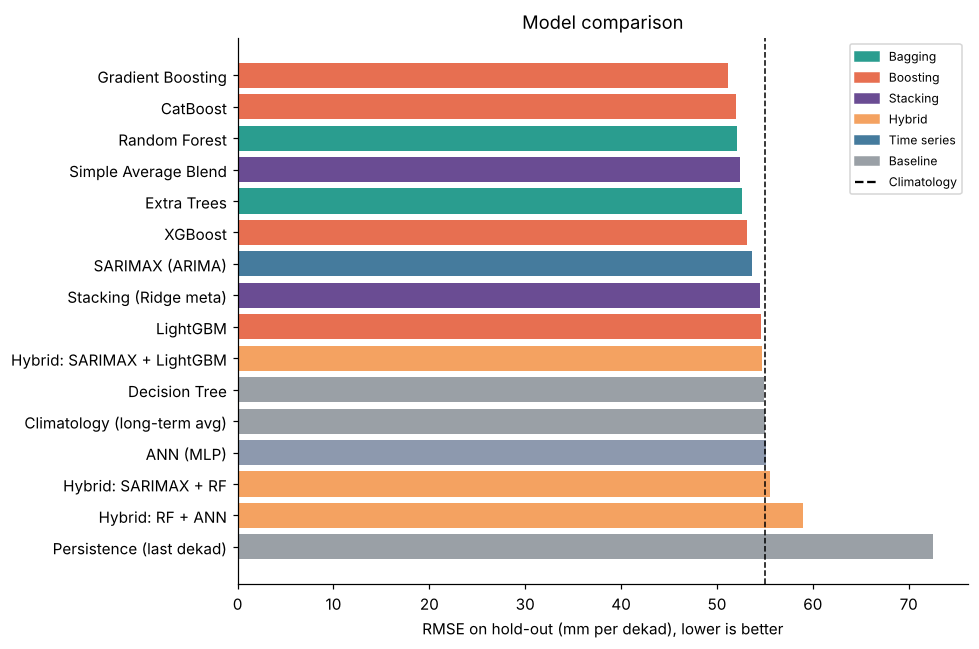

Best model in each family:


,Model,RMSE,MAE,R2,Skill vs climatology
Family,,,,,
Boosting,Gradient Boosting,51.153,34.633,0.551,0.070
Bagging,Random Forest,52.140,35.810,0.534,0.052
Stacking,Simple Average Blend,52.408,35.603,0.529,0.047
Time series,SARIMAX (ARIMA),53.694,36.531,0.505,0.024
Hybrid,Hybrid: SARIMAX + LightGBM,54.678,37.176,0.487,0.006
Baseline,Decision Tree,54.935,37.495,0.482,0.002
Neural net,ANN (MLP),55.167,38.707,0.478,-0.003


In [8]:
fig, ax = plt.subplots(figsize=(9, 6))
colors = {'Baseline': '#9aa0a6', 'Bagging': '#2a9d8f', 'Bagging family': '#2a9d8f', 'Boosting': '#e76f51', 'Stacking': '#6a4c93',
          'Hybrid': '#f4a261', 'Time series': '#457b9d', 'Neural net': '#8d99ae'}
r = res.iloc[::-1]
ax.barh(r.Model, r.RMSE, color=[colors[f] for f in r.Family]); ax.axvline(rm_clim, color='k', ls='--', lw=1, label='Climatology baseline')
ax.set_xlabel('RMSE on hold-out (mm per dekad), lower is better'); ax.legend(); ax.set_title('Model comparison')
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in ['#2a9d8f', '#e76f51', '#6a4c93', '#f4a261', '#457b9d', '#9aa0a6']]
ax.legend(handles + [plt.Line2D([], [], color='k', ls='--')], ['Bagging', 'Boosting', 'Stacking', 'Hybrid', 'Time series', 'Baseline', 'Climatology'], loc='upper right', fontsize=8)
plt.tight_layout(); plt.savefig('artifacts/model_comparison.png', dpi=140); plt.show()

print('Best model in each family:')
res.groupby('Family').first()[['Model', 'RMSE', 'MAE', 'R2', 'Skill vs climatology']].sort_values('RMSE').round(3)


**Reading the leaderboard.** Gradient Boosting has the lowest RMSE (51.2 mm per dekad, R² 0.55), but the top five models span only about 1.5 mm. The model families matter less than the choice of features here. The SARIMAX baseline alone (53.7) beats climatology (55.0), the two hybrids built on tree residuals do not improve on their parents, and RF + ANN is worst of the learned models.


### Is the ranking real or noise? Bootstrap confidence intervals
We resample whole dekads (so all districts in a dekad stay together, preserving spatial correlation) and recompute RMSE 300 times.

In [9]:
dates = test['date'].values; ud = np.unique(dates); idx = {d: np.where(dates == d)[0] for d in ud}
rng = np.random.default_rng(SEED); names = list(res.Model[:5]) + ['Climatology (long-term avg)']
names = list(dict.fromkeys(names)); boot = {n: [] for n in names}
for _ in range(300):
    ii = np.concatenate([idx[d] for d in rng.choice(ud, len(ud))])
    for n in names: boot[n].append(np.sqrt(np.mean((y_te[ii] - P[n][ii]) ** 2)))
ci = pd.DataFrame({n: [np.mean(v), np.percentile(v, 2.5), np.percentile(v, 97.5)] for n, v in boot.items()}, index=['mean RMSE', '2.5%', '97.5%']).T
ci.round(2)

,mean RMSE,2.5%,97.5%
Gradient Boosting,50.69,40.23,64.58
CatBoost,51.54,40.59,64.81
Random Forest,51.79,41.99,64.40
Simple Average Blend,51.98,41.37,65.02
Extra Trees,52.22,41.51,65.57
Climatology (long-term avg),54.34,41.23,70.50



**Reading the intervals.** The 95% intervals of the top models overlap heavily with each other and with climatology (Gradient Boosting 40 to 65, climatology 41 to 71). With a single 49-dekad hold-out we should treat the top five models as a statistical tie and not over-claim a winner.


### Forecast vs reality over the hold-out (island-wide mean) and by season

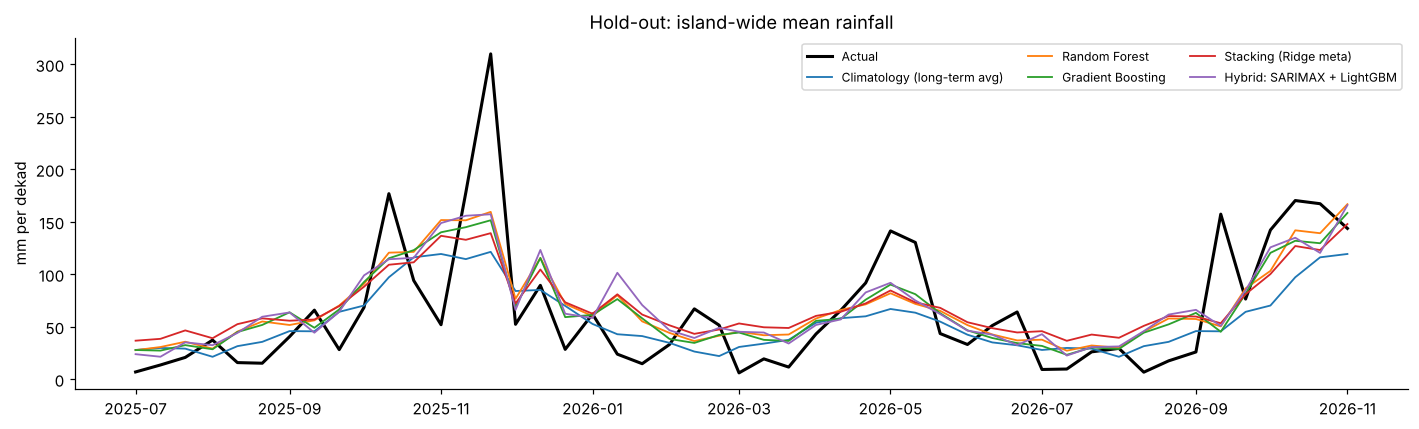

RMSE by season (mm per dekad):


,Climatology (long-term avg),Random Forest,Gradient Boosting,Stacking (Ridge meta),Hybrid: SARIMAX + LightGBM
SW monsoon (May-Sep),46.2,48.1,47.1,49.5,48.8
Inter-monsoon,73.7,63.1,62.5,67.8,65.7
NE monsoon (Dec-Feb),34.0,39.5,37.2,38.3,47.3


In [10]:
sel = ['Climatology (long-term avg)', res.Model[res.Family.isin(['Bagging'])].iloc[0], res.Model[res.Family == 'Boosting'].iloc[0],
       'Stacking (Ridge meta)', res.Model[res.Family == 'Hybrid'].iloc[0]]
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(test.groupby('date')['rfh'].mean(), 'k', lw=2, label='Actual')
for n in sel: ax.plot(test.assign(p=P[n]).groupby('date')['p'].mean(), lw=1.2, label=n)
ax.set_ylabel('mm per dekad'); ax.legend(ncol=3, fontsize=8); ax.set_title('Hold-out: island-wide mean rainfall'); plt.tight_layout(); plt.show()

season = test['monsoon'].map({0: 'Inter-monsoon', 1: 'SW monsoon (May-Sep)', 2: 'NE monsoon (Dec-Feb)'})
cmp = pd.DataFrame({n: {s: np.sqrt(np.mean((y_te[season == s] - P[n][season == s]) ** 2)) for s in season.unique()} for n in sel}).round(1)
print('RMSE by season (mm per dekad):'); cmp


**Reading the seasonal table.** The tree ensembles clearly beat climatology in the **inter-monsoon** periods (RMSE about 62 to 63 vs 73.7, roughly 15% lower), when convective storms and cyclone-related rain make the calendar a weak guide. In the two **monsoon** seasons rainfall is regular and the long-term average is already hard to beat (SW: 46.2 vs 47 to 50; NE: 34.0 vs 37 to 40). The SARIMAX + LightGBM hybrid is notably worse in the NE monsoon (47.3).


## 6. Interpretation: what drives the predictions?

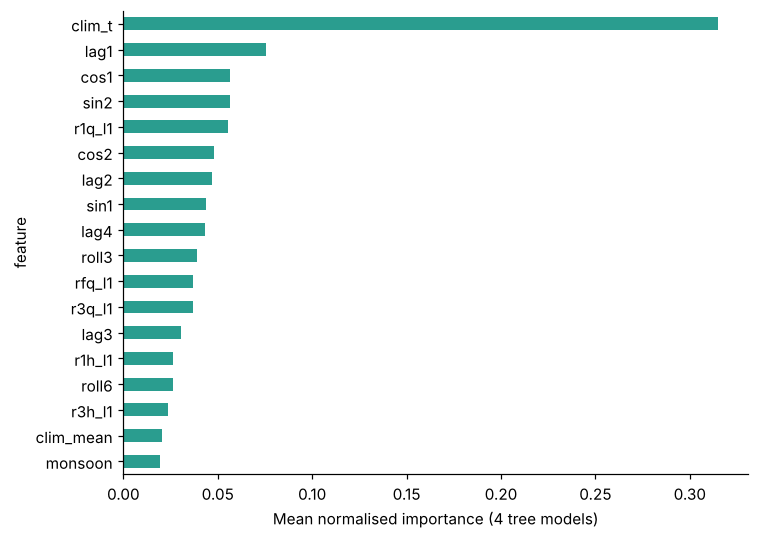

In [11]:
imp = pd.DataFrame({'feature': BASE_FEATS,
    'Random Forest': F['models']['Random Forest'].feature_importances_,
    'XGBoost': F['models']['XGBoost'].feature_importances_,
    'LightGBM': F['models']['LightGBM'].booster_.feature_importance('gain'),
    'CatBoost': F['models']['CatBoost'].get_feature_importance()})
for c in imp.columns[1:]: imp[c] = imp[c] / imp[c].sum()
imp['mean'] = imp.iloc[:, 1:].mean(axis=1); imp = imp.sort_values('mean', ascending=False)
imp.to_csv('artifacts/feature_importance.csv', index=False)
imp.set_index('feature')['mean'].iloc[::-1].plot.barh(figsize=(7, 5), color='#2a9d8f'); plt.xlabel('Mean normalised importance (4 tree models)'); plt.tight_layout(); plt.show()

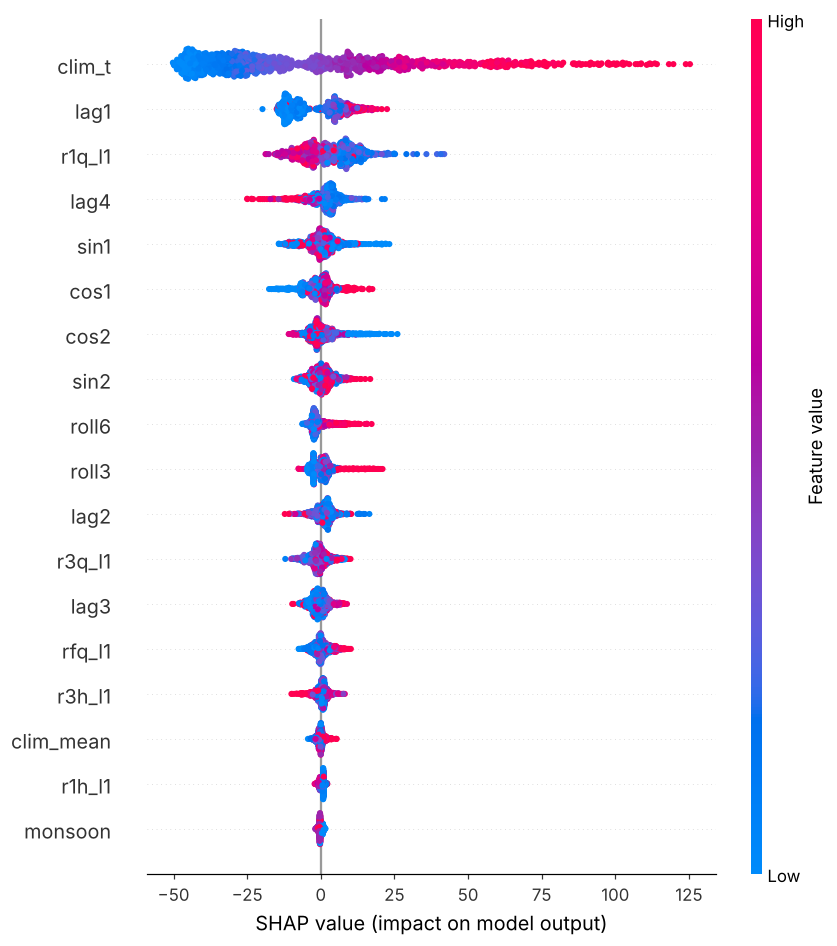

In [12]:
import shap
sv = shap.TreeExplainer(F['models']['LightGBM']).shap_values(test[BASE_FEATS])
shap.summary_plot(sv, test[BASE_FEATS], show=False); plt.tight_layout(); plt.savefig('artifacts/shap_summary.png', dpi=140, bbox_inches='tight'); plt.show()


**Reading the importance charts.** The long-term average for the target dekad (`clim_t`, about 31% of importance) dominates, followed by last dekad's rainfall (`lag1`), the seasonal sine/cosine terms and the previous dekad's 1-month anomaly. The models are mostly learning *the calendar plus a little persistence*. SHAP agrees: high `clim_t` pushes the forecast up, and a wet previous dekad adds a smaller amount on top.


In [13]:
best = res.Model[~res.Family.isin(['Baseline'])].iloc[0]
dist = pd.DataFrame({'district': test['district'], 'se': (y_te - P[best]) ** 2, 'se_c': (y_te - P['Climatology (long-term avg)']) ** 2}).groupby('district').mean() ** 0.5
dist.columns = [f'RMSE {best}', 'RMSE climatology']; dist['skill'] = 1 - dist.iloc[:, 0] / dist.iloc[:, 1]
print(f'Per-district performance of best non-baseline model: {best}'); dist.sort_values('skill', ascending=False).round(2)

Per-district performance of best non-baseline model: Gradient Boosting


,RMSE Gradient Boosting,RMSE climatology,skill
district,,,
Kegalle,60.63,73.31,0.17
Gampaha,54.90,65.49,0.16
Mannar,34.12,40.61,0.16
Mullaitivu,37.72,44.12,0.15
Jaffna,39.03,45.63,0.14
Matale,44.55,50.66,0.12
Kandy,54.07,61.46,0.12
Vavuniya,43.31,48.68,0.11
Kurunegala,47.22,52.87,0.11



**Per-district reading.** The best ensemble gains the most in Kegalle, Gampaha, Mannar, Mullaitivu and Jaffna (about 14 to 17% lower RMSE than climatology) and gains nothing in Kalutara, Galle and Anuradhapura. The very wet south-west coast (Kalutara RMSE about 86 mm per dekad) has such extreme rainfall variability that none of the models can improve on the average.

## Conclusions
**Bagging vs boosting vs stacking vs hybrid.**
* **Bagging and boosting are effectively tied.** Gradient Boosting (RMSE 51.2), CatBoost (52.0) and Random Forest (52.1) are within one mm of each other, inside the bootstrap noise. XGBoost and LightGBM landed slightly lower with default-style settings and no hyper-parameter search.
* **Stacking did not beat its best member** (54.5 vs 52.1 for the Random Forest). The five base learners make highly correlated errors, and the meta-learner only has about 2,500 out-of-fold rows to learn from, so it adds variance. The *simple average blend* (52.4) was safer.
* **Hybrids did not help here.** SARIMAX + LightGBM (54.7) matches plain LightGBM; SARIMAX + RF (55.5) and RF + ANN (59.0) are worse than the Random Forest alone. A hybrid only pays off when the first model leaves *structured* residuals. Here the lag and seasonal features already give the trees that structure, and the remaining residual is mostly weather noise, which a second model just memorises.
* **All of it is only modestly better than climatology** (best skill +7%), and persistence is far worse (-32%). Ten-day rainfall is intrinsically hard to forecast from rainfall history alone.
* **Ensembles help most when the calendar is least informative:** during the inter-monsoon periods (about 15% lower error than climatology).

**Limitations.** Only 4.8 years of data (about 3,000 training rows); one chronological hold-out of 49 dekads; light tuning only; satellite-estimated rainfall (CHIRPS) rather than gauge data; the latest 100 district-dekads are `prelim`. No ocean or atmosphere predictors.

**Next steps.** Add ENSO/Indian Ocean Dipole indices, sea-surface temperature and humidity; extend the history to 1981 (CHIRPS goes back that far); tune with time-series cross-validation; forecast the 1-month total (more predictable than 10 days).


## 7. Export for the dashboard
Models are **re-fitted on all available data** (including the hold-out) before deployment. The honest accuracy numbers above come from the hold-out run. The same pipeline also produces the forecast for the next, not yet observed dekad.

In [14]:
t0 = time.time(); FAR = pd.Timestamp('2100-01-01')
full = make_panel(raw, add_next=True); full['arima'] = arima_feature(full, FAR)
known = full[full.rfh.notna()].sort_values('date').reset_index(drop=True); nxt = full[full.rfh.isna()].reset_index(drop=True)
F2 = fit_all(known); P2 = predict_all(F2, nxt)
fc = nxt[['date', 'PCODE', 'district']].copy()
for n, p in P2.items(): fc[n] = p
fc.to_csv('artifacts/latest_forecast.csv', index=False)
print('Forecast dekad starting', nxt.date.iloc[0].date(), f'| refit + forecast took {time.time()-t0:.0f}s')

slug = lambda s: re.sub(r'[^a-z0-9]+', '_', s.lower()).strip('_')
files = {}
for n, m in F2['models'].items(): files[n] = f'models/{slug(n)}.joblib'; joblib.dump(m, files[n], compress=3)
joblib.dump(F2['stack_meta'], 'models/stack_meta.joblib'); joblib.dump(F2['ann_res'], 'models/rf_ann_residual.joblib')
test_out = test[['date', 'PCODE', 'district', 'rfh']].rename(columns={'rfh': 'Actual'})
for n, p in P.items(): test_out[n] = p
test_out.to_csv('artifacts/predictions.csv', index=False)
res.to_csv('artifacts/metrics.csv', index=False); ci.to_csv('artifacts/bootstrap_ci.csv')
clim = panel.groupby(['PCODE', 'dekad'])['rfh_avg'].mean().reset_index(); clim.to_csv('artifacts/climatology.csv', index=False)
last = known.sort_values('date').groupby('PCODE').tail(1)[['PCODE', 'rfh', 'lag1', 'lag2', 'lag3', 'r1h', 'r3h', 'rfq', 'r1q', 'r3q', 'clim_mean']]
last.rename(columns={'rfh': 'lag1_new', 'lag1': 'lag2_new', 'lag2': 'lag3_new', 'lag3': 'lag4_new'}).to_csv('artifacts/latest_state.csv', index=False)
known[['date', 'PCODE', 'district', 'rfh', 'rfh_avg']].to_csv('artifacts/history.csv', index=False)
json.dump({'base_feats': BASE_FEATS, 'districts': DISTRICTS, 'model_files': files, 'stack_bases': STACK_BASES, 'test_start': str(TEST_START.date()),
           'last_observed': str(known.date.max().date()), 'next_dekad': str(nxt.date.iloc[0].date()), 'family': FAMILY},
          open('artifacts/meta.json', 'w'), indent=1)
print('Saved:', sorted(os.listdir('models')))

Forecast dekad starting 2026-11-11 | refit + forecast took 35s


Saved: ['ann_mlp.joblib', 'catboost.joblib', 'decision_tree.joblib', 'extra_trees.joblib', 'gradient_boosting.joblib', 'lightgbm.joblib', 'random_forest.joblib', 'rf_ann_residual.joblib', 'stack_meta.joblib', 'xgboost.joblib']


## 8. How to run the dashboard
```
pip install -r requirements.txt
streamlit run app.py
```